![Nagłówek - Fundusze Europejskie dla Rozwoju Społecznego, Rzeczpospolita Polska, Dofinansowane Przez Unię Europejską i Politechnika Wrocławska](./img/header.png)

# Laboratorium kursu Wstęp do Sztucznej Inteligencji
## Optymalizacja w sztucznej inteligencji

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import sympy as sp
import folium

In [2]:
from helpers import *

## Czym jest optymalizacja?

Codzienne życie nie jest łatwe. Wiąże się z wieloma zadaniami, które trzeba zaplanować i  wykonać, np.
* Jak dojechać z domu na uczelnię w najkrótszym czasie? 
* Jak spakować się tylko do plecaka na weekendowy wyjazd, żeby nie musieć brać ze sobą walizki? 
* Jak poradzić sobie, gdy pieniędzy na dany miesiąc (wypłaty, stypendium, kieszonkowego) zostało już mało, a do kolejnej wypłaty został jeszcze tydzień? 
* Jak zaplanować gotowanie, aby ziemniaki i kotlet były gotowe w tym samym momencie?

Prawdopodobnie choć jeden z tych problemów jest Ci znany. Rozwiązując je wykonujemy *optymalizację*, czyli przeprowadzamy **proces znajdowania najlepszego rozwiązania**. 
Optymalizacja nie jest tylko domeną sztucznej inteligencji - to naturalny proces, który wykonujemy codziennie, dążąc do osiągnięcia najlepszego rezultatu przy ograniczonych zasobach (czasie, pieniądzach, energii).

* Planujesz trasę na uczelnię lub wykorzystujesz w tym celu dedykowane narzędzia.
    * **Cel:** Dojechać z domu na uczelnię.
    * **Przedmiot optymalizacji:** Czas podróży.
    * **Zmienne:** Przebieg trasy.
    * **Ograniczenia:** Roboty drogowe, limity prędkości.


* Wyjeżdżasz na weekend i chcesz wziąć tylko plecak.
    * **Cel:** Zapakować jak najwięcej potrzebnych przedmiotów.
    * **Przedmiot optymalizacji:** Użyteczność zabranych rzeczy lub objętość upchniętych ubrań.
    * **Zmienne:** Przedmioty które zabierasz i ich ułożenie w plecaku (np. zwinięcie w rulon, przegroda w którą je spakujesz).
    * **Ograniczenia:** Wymiary plecaka, wygoda noszenia go.


* Musisz przeżyć jeszcze tydzień, a pieniędzy masz już niewiele.
    * **Cel:** Przeżyć, nie być głodnym.
    * **Co optymalizujemy (szukamy kompromisu):** Koszt zakupionych przedmiotów, dostarczana przez nie energia i wartości odżywcze, stosunek jakości do ceny.
    * **Zmienne:** co i w jakiej ilości kupujesz.
    * **Ograniczenia:** Suma posiadanych w portfelu pieniędzy.


* Chcesz podać niedzielny obiad - rosół, kotleta, ziemniaki i dodatek (np. surówkę) tak, aby pierwsza była zupa, a później drugie danie. Żeby było smacznie, jedzenie powinno być ciepłe.
    * **Cel:** Zjeść ciepły obiad dwudaniowy.
    * **Co optymalizujemy (minimalizujemy):** Czas przygotowania, różnicę czasu gotowości dań, różnicę temperatur między daniami.
    * **Zmienne:** Moment rozpoczęcia gotowania składników (rosół potrzebuje 4 godziny, ziemniaki potrzebują 20 min, kotlet 5 min, a surówkę już masz).
    * **Ograniczenia:** Liczba palników na kuchence, dostępne narzędzia, czas przygotowania poszczególnych składników, czas potrzebny na zjedzenie rosołu.

Celem optymalizacji jest znalezienie najlepszego rozwiązania, ale w praktyce często wystarczy, gdy rozwiązanie jest *wystarczająco dobre*, a da się je znaleźć szybko (np. zrezygnowanie z zapakowania jednej koszulki, lub zostawienie ziemniaków po ugotowaniu w garnku, aby nie ostygły zbyt szybko). Wtedy oprócz jakości rozwiązania liczy się też koszt jego szukania. W podobny sposób działa mózg. Jest on tzw. "skąpcem poznawczym"<sup>1</sup> i woli uprościć problem lub zdać się na szybkie (wydajne) rozwiązanie, niż sporym wysiłkiem szukać rozwiązania idealnego.

Daniel Kahneman, autor książki "Pułapki myślenia. O myśleniu szybkim i wolnym" (Thinking, Fast and Slow<sup>2</sup>) opisuje nasze myślenie jako współpracę dwóch systemów:

* System 1 (Szybki, Instynktowny, Tani) działa automatycznie, bez znaczącego wysiłku umysłowego. To np. wynik działania 2+2, obieranie ziemniaków, jazda samochodem pustą drogą. Są to działania relatywnie proste, wykonane wiele razy, które mózg dobrze zna. Mózg nie "liczy" wyniku 2+2, on go "pamięta". W informatyce do takich zadań wykorzystujemy tzw. Lookup Table (tablica wyników) lub Cache. To jest optymalizacja przez zapamiętywanie - memoizacja.

* System 2 (Wolny, Analityczny, Drogi) wymaga uwagi i skupienia. Zużywa przy tym sporo energii. To np. wynik działania $2^\pi$, parkowanie równoległe "na styk", nauka nowej gry planszowej. Mózg musi wykonać wszystkie procesy krok po kroku. W informatyce byłby to skomplikowany algorytm, np. poszukiwanie najkrótszej ścieżki bez heurystyki. 

Mózg optymalizuje swoje zasoby, starając się jak najczęściej używać Systemu 1, pozostawiając System 2 tylko na nadzwyczajne (nieznane / niewystarczająco znane) sytuacje. Podobny kompromis da się znaleźć w metodach SI - przegląd zupełny z Laboratorium 1 sprawdza wszystkie kombinacje z siatki, ale jest kosztowny. Niektóre metody heurystyczne z Laboratorium 3 (np. metoda najbliższego sąsiada czy GBFS) i gradient prosty z tego laboratorium są szybkie, ale nie gwarantują najlepszego wyniku. W dalszej części laboratorium skupimy się na „optymalizacji” jako szukaniu minimum funkcji.

## Optymalizacja w Sztucznej Inteligencji

Choć w Sztucznej Inteligencji (SI) pojęcie optymalizacji jest szerokie, w ramach tej listy zajmiemy się szukaniem minimum funkcji, a w szczególności takim doborem parametrów modelu, aby ten jak najlepiej odwzorowywał dostarczone dane. Co takie działanie ma na celu?

Wiele modeli SI, nieważne czy służą do rozpoznawania obrazów, tłumaczenia języka, czy przewidywania cen akcji, to w rzeczywistości funkcje o wielu parametrach. Aby taki model był skuteczny, powinien dobrze oddawać rzeczywistość. To z kolei wymaga, aby funkcja (model) była jak najlepiej dopasowana do tej rzeczywistości. Skąd jednak wiemy, jakie parametry dobrać, aby uzyskać "najlepsze" dopasowanie?

Dopasowaniem funkcji do danych zajmowaliśmy się już w pierwszym laboratorium. Szukaliśmy wtedy takich współczynników wielomianu, aby jak najlepiej oddawał on zachowanie danych w określonym przedziale. Najpierw dobieraliśmy je ręcznie, a następnie przeglądem zupełnym. Wróćmy do tych samych danych. Poniżej wielomian 4. stopnia z już dobranymi współczynnikami.

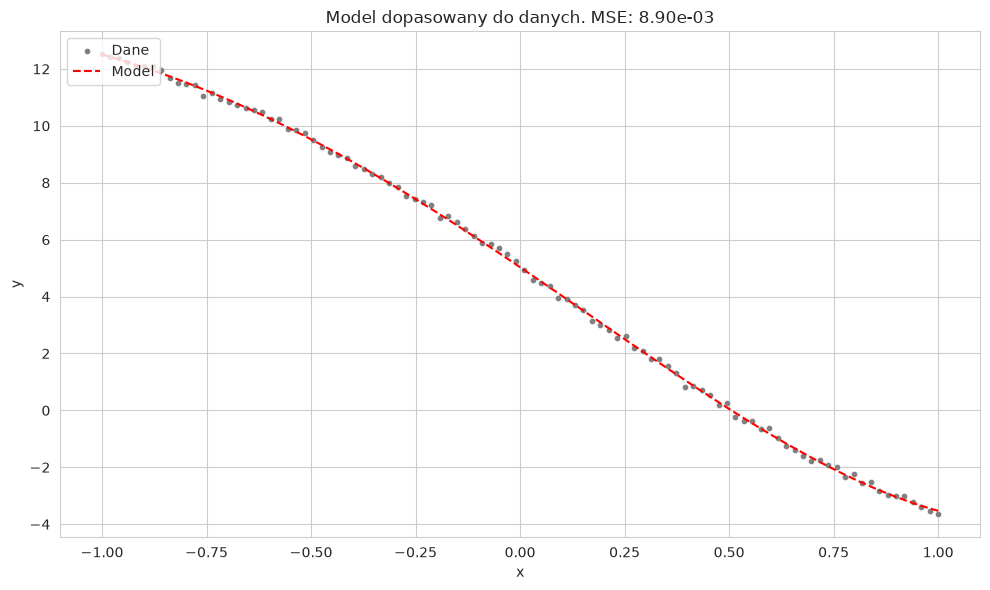

In [3]:
data = pd.read_csv(f"data/example_1.csv")
x = data["x"]
y = data["y"]

poly_coeffs = {
    "a_4": 0.57,
    "a_3": 1.94,
    "a_2": -1.11,
    "a_1": -9.96,
    "a_0": 5.03
}

poly_coeffs = [i for _, i in sorted(poly_coeffs.items(), key=lambda x: x[0])]
y_best = sum(c * x**i for i, c in enumerate(poly_coeffs))
mse = np.mean((y - y_best) ** 2)

sns.set_style("whitegrid")
plt.figure(figsize=(10, 6))
sns.scatterplot(x=x, y=y, color="gray", s=20, label="Dane")
sns.lineplot(x=x, y=y_best, color="red", linestyle="--", label="Model")
plt.title(f"Model dopasowany do danych. MSE: {mse:.2e}")
plt.xlabel("x")
plt.ylabel("y")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

W Laboratorium 1 znalezienie parametrów akceptowalnie dobrego modelu było stosunkowo proste:
1. Wykonaliśmy wstępne dopasowanie ręcznie
2. Znaleźliśmy dokładniejsze dopasowanie metodą przeglądu zupełnego w założonym zakresie wartości parametrów

Czy takie podejście zawsze będzie skuteczne?

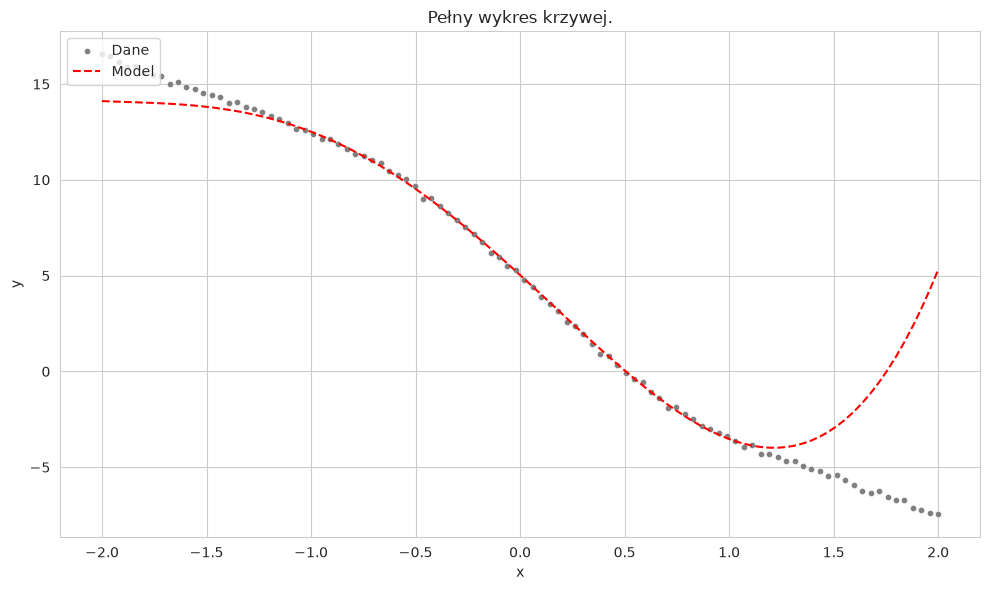

In [4]:
data = pd.read_csv(f"data/example_2.csv")
x = data["x"]
y = data["y"]
y_best = sum(c * x**i for i, c in enumerate(poly_coeffs))

sns.set_style("whitegrid")
plt.figure(figsize=(10, 6))
sns.scatterplot(x=x, y=y, color="gray", s=20, label="Dane")
sns.lineplot(x=x, y=y_best, color="red", linestyle="--", label="Model")
plt.title(f"Pełny wykres krzywej.")
plt.xlabel("x")
plt.ylabel("y")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

W przypadku kształtu mniej oczywistego, znalezienie współczynników jest trudniejsze, a skomplikowanie przeglądu zupełnego eksploduje. Potrzebujemy więc innej metody optymalizacji, która nie sprawdza wszystkich kombinacji, tylko w każdym kroku stara się zmniejszyć błąd dopasowania. Poznamy ją najpierw na prostszych przykładach.

## Optymalizacja z wykorzystaniem pochodnej

W ramach tej listy zajmiemy się jednym z najczęściej wykorzystywanych algorytmów optymalizacyjnych w całym uczeniu maszynowym: **Gradient Descent** (GD), czyli **algorytmem gradientu prostego**. 

Angielska nazwa algorytmu ma 2 części nazwy: **Gradient** i **Descent**.

Zajmijmy się najpierw Descent czyli zejściem / spadkiem. W optymalizacji zazwyczaj szukamy minimum funkcji - taka konwencja. To tak, jakby szukać doliny będąc w górach - trzeba zejść w dół po zboczu (gdybyśmy maksymalizowali, szukalibyśmy szczytu i szli w górę). Aby zejść w dół, musimy wiedzieć, w którą stronę teren opada. Jakie matematyczne narzędzie służy do sprawdzenia nachylenia funkcji? 

Tutaj mamy do czynienia z drugą częścią nazwy, czyli **gradientem funkcji**. Formalnie jest to wektor złożony z pochodnych cząstkowych funkcji wielu zmiennych. Na potrzeby laboratorium będziemy traktować go jako uogólnienie **pochodnej**. Z matematyki ze szkoły średniej wiesz, że pochodna służy do określenia szybkości zmian wartości funkcji (jej nachylenia):

* Jeśli jest dodatnia: $f'(x) > 0$, funkcja rośnie wraz ze wzrostem $x$
* Jeśli jest ujemna $f'(x) < 0$, funkcja maleje wraz ze wzrostem $x$
* Jeśli $f'(x) = 0$, to funkcja nie rośnie ani nie maleje. Mamy do czynienia z punktem stacjonarnym. Szczególnymi przypadkami takich punktów są minima (doliny) albo maksima (szczyty). Gradient prosty zatrzymuje się w punkcie, w którym pochodna jest równa 0.

Te własności pochodnej pozwalają nam obrać prostą, intuicyjną strategię:

1.  Znajdujemy się w punkcie $x_i$.
2.  Sprawdzamy nachylenie w danym miejscu (czyli obliczamy pochodną $f'(x_i)$).
3.  Jeśli nachylenie jest **dodatnie** ($f'(x_i) > 0$), to znaczy, że wraz ze wzrostem $x$ rośnie też $y$. "Idąc w prawo", idziemy w górę. Aby dotrzeć do minimum, czyli np. zejść z góry, musimy iść w **lewo**.
4.  Jeśli nachylenie jest **ujemne** ($f'(x_i) < 0$), to znaczy, że wraz ze wzrostem $x$ maleje $y$, czyli idąc w prawo idziemy w dół. Aby dotrzeć do minimum, musimy iść w **prawo**.

Oba te przypadki można opisać jednym wzorem:

$$x_{i+1} = x_i - \eta \cdot f'(x_i)$$

Gdzie:
* $x_{i+1}$ to nasze następne położenie.
* $x_i$ to nasze obecne położenie.
* $f'(x_i)$ to pochodna w obecnym punkcie.
* $\eta$ to **współczynnik uczenia** (ang. *learning rate*). Mówi on, jak **duży krok** robimy.
    * Jeśli $\eta$ jest za małe, to tak, jakby poruszać się malutkimi kroczkami - zejście zajmie wieczność.
    * Jeśli $\eta$ jest za duże, to tak, jakby poruszać się wielkimi skokami - można "przeskoczyć" dolinę i wylądować na górze po drugiej stronie doliny. Jeżeli skok będzie wystarczająco duży, możemy znaleźć się jeszcze wyżej niż byliśmy. Wtedy w kolejnym kroku skok będzie jeszcze większy i algorytm z każdym krokiem będzie oddalać się od minimum.

Funkcję, której minimum szukamy, będziemy nazywać **funkcją kosztu**.

### 🧑‍🎓 Zadanie

Na podstawie wzoru powyżej, uzupełnij funkcję `compute_new_x` i wykonaj komórkę. Upewnij się, że funkcja działa poprawnie (pomoże w tym wygenerowana animacja).

Poniższy kod wizualizuje algorytm Gradient Descent na prostej funkcji kwadratowej (paraboli). Funkcja kształtem przypomina łagodną, pojedynczą dolinę. Do obliczeń używamy biblioteki **SymPy**, która liczy na wzorach tak jak człowiek, tj., `sp.symbols('x')` tworzy symbol $x$, `sp.diff(f, x)` oblicza pochodną wzoru `f` względem $x$, a `sp.lambdify(x, f)` zamienia wzór na zwykłą wykonywalną funkcję Pythona, do której można podstawiać liczby.

Przeanalizuj tabelę wyników. Sprawdź, jak zmienia się rozmiar kroku oraz gradient wraz ze zbliżaniem się do minimum.

In [12]:
def compute_new_x(x, df, learning_rate):
    """
    Wykonuje pojedynczy krok algorytmu Gradient Descent dla funkcji jednej zmiennej.

    Args:
        x (float): Aktualna pozycja (wartość parametru), w której się znajdujemy.
        df (callable): Funkcja obliczająca pochodną (nachylenie) w danym punkcie. 
                            Musi przyjmować jeden argument i zwracać liczbę.
        learning_rate (float): Współczynnik uczenia (eta). Określa wielkość kroku.
                            Decyduje o tym, jak daleko przesuniemy się w jednej iteracji.

    Returns:
        float: Nowa, zaktualizowana pozycja x.
    """
    # Oblicz wartość pochodnej w punkcie x
    derivative_value = df(x)
    
    # Zwróć nową pozycję x
    return x - learning_rate*derivative_value


learning_rate = 0.1
# Funkcja i jej pochodna
x = sp.symbols('x')
f = x**2 - 6*x + 10
df = sp.diff(f, x)  # Pochodna: 2x - 6

f_num = sp.lambdify(x, f, 'numpy')
f_df_num = sp.lambdify(x, df, 'numpy')

make_parabolic_example(f_num, f_df_num, learning_rate, compute_new_x)


Generowanie animacji...
Podsumowanie optymalizacji:
- Start: x = 0.0000
- Koniec (po 25 iteracjach): x = 2.9887
- Gradient końcowy: -0.0227
Tabela przebiegu optymalizacji (kluczowe kroki):


,Iteracja,Pozycja x,Pochodna f'(x),Długość kroku η·|f'(x)|,Koszt f(x)
0,0,0.000000,-6.000000,0.600000,10.000000
1,6,2.213568,-1.572864,0.157286,1.618475
2,12,2.793842,-0.412317,0.041232,1.042501
3,18,2.945957,-0.108086,0.010809,1.002921
4,25,2.988666,-0.022667,0.002267,1.000128


W rzeczywistości przypadki takie jak powyżej, gdzie algorytm jednoznacznie zbiega do jednego minimum, są rzadkością. W wielu ważnych zastosowaniach (np. w sieciach neuronowych) funkcja kosztu ma wiele minimów lokalnych w krajobrazie funkcji, czyli wielu miejsc, w których funkcja ma wartość mniejszą niż w punktach dookoła, a pochodna jest równa 0. Chcielibyśmy jednak znajdować najmniejszą wartość w całej dziedzinie, czyli tzw. minimum globalne, czego algorytm gradientu prostego nie gwarantuje.

### 🧑‍🎓 Zadanie

Używając kodu poniżej zbadaj:
* W jaki sposób learning_rate wpływa na działanie algorytmu Gradient Descent 
* W jaki sposób pozycja początkowa (`start`) wpływa na znajdowane rozwiązania

Zapisz wnioski.

Wizualizacja dotyczy funkcji o bardziej skomplikowanym kształcie (wiele wzniesień i dolin, z kilkoma minimami lokalnymi). Najniższa wartość tej funkcji to 0 w minimum globalnym.

Zwróć uwagę, czy algorytm zatrzymał się w minimum lokalnym (koszt wyższy niż 0), czy znalazł globalne. Zależy to bezpośrednio od punktu początkowego `start` zdefiniowanego w scenariuszu i od współczynnika uczenia `learning_rate`.


In [18]:
show_trace = True
steps = 100 # Liczba kroków algorytmu
learning_rate = 0.05

scenarios = [
    {"name": "Lewy",   "start": -1.9, "color": "red"},
    {"name": "Środkowy", "start": -0.6, "color": "green"},
    {"name": "Prawy",  "start":  1.9, "color": "blue"}
]

# Definicja symboliczna funkcji i gradientu
x = sp.symbols('x')
f_sym = x**6 - 5*x**4 + 7*x**2
f_prime_sym = sp.diff(f_sym, x)

# Konwersja na funkcje numeryczne
f_num = sp.lambdify(x, f_sym, 'numpy')
f_df_num = sp.lambdify(x, f_prime_sym, 'numpy')


make_higher_order_example(f_num, f_df_num, scenarios, learning_rate, compute_new_x, steps, show_trace)


Podsumowanie optymalizacji dla podanych scenariuszy (3):
[Lewy] Start: x = -1.9000, Koniec (po 100 iteracjach): x = -0.0000, Gradient końcowy: -0.0000
[Środkowy] Start: x = -0.6000, Koniec (po 100 iteracjach): x = -0.0000, Gradient końcowy: -0.0000
[Prawy] Start: x = 1.9000, Koniec (po 100 iteracjach): x = 0.0000, Gradient końcowy: 0.0000
Tabela przebiegu optymalizacji (kluczowe kroki dla każdego scenariusza):


,Scenariusz,Iteracja,Pozycja x,Koszt f(x)
0,Lewy,0,-1.900000e+00,7.155381e+00
1,Lewy,50,-1.682277e-29,1.981040e-57
2,Lewy,100,-1.207704e-55,1.020983e-109
3,Środkowy,0,-6.000000e-01,1.918656e+00
4,Środkowy,50,-1.412576e-26,1.396760e-51
5,Środkowy,100,-1.014085e-52,7.198585e-104
6,Prawy,0,1.900000e+00,7.155381e+00
7,Prawy,50,1.682277e-29,1.981040e-57
8,Prawy,100,1.207704e-55,1.020983e-109


Wnioski:
pozycja start ma bezpośredni wływ na minimul loklane jakie znajdziemy, np. środkowy miał pozycje startową najbliższą minimum globalnego co pozwoliło mu jez naleźć. W pozostałych scrnariuszach byliśmy bliżej innych minimów lokalnych przez co to właśnie je znalezliśmy.
Zbyt mały learning rate uniemożli nam znalezinie minimum przez to że poruszamy się zbyt wolno. Potrzebna by była znacznie większa liczba iteracji co wydłuża cały proces.
Za duży learning rate również może być problemem, w tym konkretnym przypadku większy learning rate pozwolił scenariuszowi lewy i prawy przeskoczyć lokalne minima i znaleźć się w globalnym ale nie jest to reguła równie dobrze przy innym krajobrazie funkcji kosztu za duże learning rate mógłby sprawidz ze bedzie odbijać się od scian i nie znajdziemy zadnego minimum.

### 🧑‍🎓 Zadanie

Znajdź pochodne funkcji $f(x) = x^2\sin(x) $ z sympy i kodu powyżej.

Podpowiedź: Druga pochodna $f(x)$ jest pierwszą pochodną jakiej funkcji? Co może oznaczać?

In [22]:
import math
# Zdefiniuj symbol 'x'
x = sp.symbols('x')

# Zdefiniuj funkcję (f(x))
f_x = x*x*sp.sin(x)

# Oblicz pierwszą pochodną (f'(x))
f_derivative = sp.diff(f_x,x)

# Oblicz drugą pochodną (f''(x))
f_second_derivative = sp.diff(f_derivative, x)

print(f"Funkcja f(x): {f_x}")
print(f"Pierwsza pochodna f'(x): {f_derivative}")
print(f"Druga pochodna f''(x): {f_second_derivative}")

Funkcja f(x): x**2*sin(x)
Pierwsza pochodna f'(x): x**2*cos(x) + 2*x*sin(x)
Druga pochodna f''(x): -x**2*sin(x) + 4*x*cos(x) + 2*sin(x)


## Gradient Descent

Wykorzystanie pochodnej ogranicza nas do funkcji jednej zmiennej. Wiemy jak poruszać się po $x$. Co jednak zrobić, gdy nasza funkcja zależy od czegoś więcej niż samego $x$? Potrzebujemy innego, ale podobnego narzędzia, bardziej uogólnionego. Wprowadźmy zatem nowe pojęcia:

1.  **Pochodna Cząstkowa** ($\frac{\partial f}{\partial x}$): To pochodna funkcji wielu zmiennych względem jednej z nich. Mówi o nachyleniu funkcji gdy poruszamy się tylko wzdłuż jednej osi (np. osi $x$), traktując wszystkie inne (np. $y$, $z$) jak stałe. Gdybyśmy próbowali zejść z góry do doliny, naszymi zmiennymi mogły być np. kierunki północ-południe i wschód-zachód. Chociaż moglibyśmy poruszać się nie tylko w tych dwóch kierunkach, pochodna cząstkowa dla kierunku północ-południe mówiłaby nam, jak zmienia się wysokość góry gdy poruszamy się idealnie w tym kierunku.
2.  **Gradient** ($\nabla f$): To **wektor** złożony ze wszystkich pochodnych cząstkowych. Gradient wskazuje kierunek **najszybszego wzrostu** funkcji (o ile funkcja jest różniczkowalna i nie obliczamy go w punkcie stacjonarnym).

$$\nabla f(x, y) = \left[ \frac{\partial f}{\partial x}, \frac{\partial f}{\partial y} \right]$$

Uwaga: tutaj $x$ i $y$ to dwie zmienne (np. współrzędne na mapie).

W wielu zmiennych gradient prosty działa dokładnie tak samo jak w jednej, tylko pochodną zastępujemy gradientem. Dla funkcji jednej zmiennej gradient to po prostu $[f'(x)]$, więc wzór poniżej sprowadza się do wzoru z poprzedniej części.

1.  Obliczamy gradient w punkcie $\mathbf{p}_i = (x_i, y_i)$ -> $\nabla f(\mathbf{p}_i)$. Wiemy, że wskazuje on kierunek najszybszego wzrostu ("w górę").
2.  Jeśli minimalizujemy, to chcemy iść "w dół", więc robimy krok w **przeciwnym kierunku** niż gradient, tak samo jak robiliśmy krok w kierunku przeciwnym do pochodnej.
3.  Długość tego kroku jest kontrolowana przez **współczynnik uczenia** (ang. *learning rate*, $\eta$) i długość wektora gradientu, tak jak zależała wcześniej od wartości pochodnej.

Czyli:

$$
\mathbf{p}_{i+1} = \mathbf{p}_i - \eta \nabla f(\mathbf{p}_i)
$$  

Tak jak dla funkcji jednej zmiennej:
* Jeśli $\eta$ jest za małe, będziemy bardzo powoli (małymi krokami) schodzić z góry.
* Jeśli $\eta$ jest za duże, możemy "przeskoczyć" dolinę i wylądować na górze "po jej drugiej stronie".

### 🧑‍🎓 Zadanie

Zaimplementuj funkcję aktualizującą pozycję w oparciu o gradient. 

Przykład pokazuje powierzchnię 2D z odpowiednikiem mapy wysokościowej. Przestrzeń ma kształt dużej okrągłej misy z jednym punktem centralnym będącym najniższym miejscem.

Obserwuj trajektorie punktów - z biegiem iteracji wartości parametrów x i y powinny się stabilizować w okolicy (0, 0), a koszt powinien maleć.


In [ ]:
def compute_new_position_with_gradient(pos, gradient_funcs, learning_rate):
    """
    Oblicza nową pozycję punktu, wykonując krok w kierunku przeciwnym do gradientu (Gradient Descent).
    
    Funkcja oblicza wektor gradientu w obecnym punkcie, korzystając z przekazanej listy
    funkcji pochodnych cząstkowych, a następnie przesuwa punkt o skalowany wektor
    w kierunku spadku wartości funkcji.

    Args:
        pos (np.ndarray): Obecne współrzędne punktu.
        gradient_funcs (list of callable): Lista funkcji obliczających pochodne cząstkowe.
        Każda funkcja przyjmuje całą pozycję `pos` (np. g(pos) dla pos=[x, y]).
        learning_rate (float): Współczynnik uczenia (step size), określający
            jak duży krok zostanie wykonany w jednej iteracji.

    Returns:
        np.ndarray: Nowa pozycja punktu po wykonaniu kroku optymalizacyjnego.
    """
    grad = ...
    grad = np.array(grad)
    return ...


show_trace = True       
steps = 50 # Liczba kroków
learning_rate = 0.005 # Współczynnik uczenia

# Definicja Matematyczna
x_sym, y_sym = sp.symbols('x y')
f_sym = 7*x_sym**2 + 7*y_sym**2

# Pochodne (Gradient)
df_dx = sp.diff(f_sym, x_sym)
df_dy = sp.diff(f_sym, y_sym)

# Konwersja na funkcje numeryczne (szybkie obliczenia)
f_num = sp.lambdify([(x_sym, y_sym)], f_sym, 'numpy')
grad_x_num = sp.lambdify([(x_sym, y_sym)], df_dx, 'numpy')
grad_y_num = sp.lambdify([(x_sym, y_sym)], df_dy, 'numpy')

# Scenariusze Startowe
scenarios = [
    {"name": "Lewy",   "start": np.array([-2.0, 1.5]), "color": "red"},
    {"name": "Środkowy",   "start": np.array([-0.5, 1.5]), "color": "white"}, # Biały kolor dla kontrastu
    {"name": "Prawy",  "start": np.array([ 2.0, -1.5]), "color": "cyan"}
]

make_2d_parabolic_example(f_num, [grad_x_num, grad_y_num], scenarios, learning_rate, compute_new_position_with_gradient, steps=steps, show_trace=show_trace)


Tak jak w przykładach z pochodną, przypadki gdzie algorytm zbiega do jednego minimum, są rzadkością. Ponownie musimy uważać na minima lokalne.

### 🧑‍🎓 Zadanie

Używając kodu poniżej zbadaj:
* W jaki sposób learning_rate wpływa na działanie algorytmu Gradient Descent dla funkcji wielu zmiennych
* W jaki sposób pozycja początkowa (`start`) wpływa na znajdowane rozwiązania

Zapisz wnioski.

Przykład wykorzystuje złożony krajobraz 3D z urozmaiconą rzeźbą terenu obejmującą wzniesienia i doliny (minima lokalne i globalne).

Punkty z różnych miejsc startowych podążą różnymi ścieżkami, co można zaobserwować w danych tabelarycznych po różnicy końcowych kosztów. W zależności od pozycji startowej powinny osiągać inne minimum.

In [ ]:
show_trace = True
steps = 50 # Liczba kroków
learning_rate = 0.05 # Współczynnik uczenia

# Definicja Matematyczna
x_sym, y_sym = sp.symbols('x y')
f_sym = 0.4*x_sym**2 + y_sym**2 - sp.cos(2*x_sym)

# Pochodne (Gradient)
df_dx = sp.diff(f_sym, x_sym)
df_dy = sp.diff(f_sym, y_sym)

# Konwersja na funkcje numeryczne (szybkie obliczenia)
f_num = sp.lambdify([(x_sym, y_sym)], f_sym, 'numpy')
grad_x_num = sp.lambdify([(x_sym, y_sym)], df_dx, 'numpy')
grad_y_num = sp.lambdify([(x_sym, y_sym)], df_dy, 'numpy')

# Scenariusze Startowe
scenarios = [
    {"name": "Lokalne (Lewe)",   "start": np.array([-3.0, 1.5]), "color": "red"},
    {"name": "GLOBALNE",         "start": np.array([-0.8, 1.5]), "color": "white"},
    {"name": "Lokalne (Prawe)", "start": np.array([3.0, -1.5]), "color": "cyan"}
]

make_3D_higher_order_example(f_num, [grad_x_num, grad_y_num], scenarios, learning_rate, compute_new_position_with_gradient, steps=steps, show_trace=show_trace)

*Wnioski*

### Minimalizacja funkcji kosztu

W pierwszym laboratorium wykorzystywaliśmy błąd średniokwadratowy (*Mean Squared Error*, MSE) do oceny jakości dopasowania funkcji do danych. Obliczaliśmy kwadraty różnic między punktami pomiarowymi a wartościami przewidywanymi przez model, a następnie uśrednialiśmy po całym zbiorze danych:

$$MSE = {1 \over n} \sum_{i=1}^n (y_i - \hat{y}_i)^2$$

Gdzie:

* $n$ – liczba próbek (obserwacji),
* $y_i$ – zmierzona (obserwowana) wartość dla próbki,
* $\hat{y}_i$ – wartość przewidywana przez model dla próbki

Funkcję, którą minimalizujemy podczas optymalizacji, nazywamy **funkcją kosztu** albo **funkcją straty** (ang. *loss*). MSE jest jedną z nich.

Dla każdej próbki porównujemy nasze predykcje $\hat{y}_i$ do wartości $y_i$. Każda taka próbka w danych jest parą wartości $(x_i, y_i)$. Gdzie jednak ma zastosowanie $x_i$?

Jeżeli potraktujemy nasze dane jako zbiór punktów wygenerowanych z użyciem funkcji $f$, pary $(x_i, y_i)$ będą opisywały wartości argumentów (wejść) i odpowiadających im wartości funkcji (wyjść) $y_i \approx f(x_i)$. 

Funkcja $f$ jest źródłem naszych danych i zazwyczaj jest nieznana. Często nawet nie mamy pojęcia jak mogłaby wyglądać:
* Jeżeli chcesz zamodelować zmianę temperatury wody w czajniku po zagotowaniu, $x$ może być czasem od jej zagotowania, $y$ wartością temperatury.
* Jeżeli chcesz zamodelować natężenie ruchu na ulicach miasta, $x$ może być godziną, $y$ liczbą samochodów.
* Jeżeli chcesz nauczyć model rozróżniać psy i koty ze zdjęć, $x$ będą zdjęcia, $y$ oznaczenia tych zdjęć ("pies" lub "kot").

O ile szkolna fizyka podpowiada nam możliwy kształt funkcji zmian temperatury wody w czajniku, a natężenie ruchu na ulicach wykazuje okresowość (cyklicznie rośnie i maleje), samodzielne wymyślenie jak wartości pikseli na zdjęciu przekładają się na klasę "pies" lub "kot" jest praktycznie niemożliwe.

Z pomocą przychodzi nam optymalizacja. Jeżeli nie znamy kształtu funkcji, możemy spróbować ją znaleźć, albo chociaż przybliżyć, czyli znaleźć takie parametry nowej funkcji $\hat{f}(x_i)$, które sprawią, że dopasowanie do danych będzie jak najlepsze, czyli błąd dopasowania będzie jak najmniejszy. Będziemy zatem minimalizować błąd dopasowania, $MSE$. Przyjmie ono formę:

$$MSE = {1 \over n} \sum_{i=1}^n (y_i - \hat{f}(x_i))^2$$

Jeżeli nasza funkcja $\hat{f}$ będzie np. funkcją kwadratową, czyli $\hat{f}(x_i) = a_2x_i^2 + a_1x_i + a_0$, $MSE$ przyjmie postać:

$$MSE = {1 \over n} \sum_{i=1}^n (y_i - (a_2x_i^2 + a_1x_i + a_0))^2$$

Co jednak będziemy optymalizować, skoro argumenty $x_i$ są ustalone w zebranych próbkach? We wcześniejszych przykładach szukaliśmy takiej wartości $x$, dla której $y$ był najmniejszy. Teraz będziemy szukać takiej funkcji $\hat{f}$ która minimalizuje błąd. Skoro o dopasowaniu do danych decyduje kształt funkcji, a ten jest definiowany przez jej parametry, musimy optymalizować parametry funkcji. Dla powyższej funkcji kwadratowej, będziemy optymalizować parametry $a_2, a_1, a_0$ - będą one tym samym, czym był $x$ w poprzednich przykładach. Oznacza to, że będziemy poszukiwać takich parametrów $a_2, a_1, a_0$ dla których wartość $MSE$ będzie najmniejsza.

W świecie rzeczywistym i tworzonych dla niego rozwiązaniach SI, nasze poszukiwane funkcje opisujące świat prawie nigdy nie zależą od jednej zmiennej. Kolorowe zdjęcie 12MP to ponad 30 mln liczb będących argumentami modelu. Wielkie modele językowe mają **miliardy** parametrów (tzw. "wag" modelu). Funkcja kosztu zależy wtedy od wszystkich parametrów naraz, dlatego potrzebujemy gradientu.



### Przykład

Dopasowanie funkcji liniowej: $y = a_1x + a_0$ do danych. Zauważ, że algorytm gradientu prostego (Gradient Descent) działa w dziedzinie parametrów funkcji. Wartość błędu zależy od danych pomiarowych i od kształtu funkcji (czyli wartości jej parametrów). Danymi sterować nie możemy, bo to informacja o świecie. Możemy za to sterować parametrami funkcji. Minimalizujemy zatem wartość błędu ($MSE$), dobierając tak parametry $a_1, a_0$, aby funkcja jak najlepiej pokrywała się z danymi.

Przestrzeń błędu to łagodna niecka o jednym wyraźnym zagłębieniu, co ułatwia znalezienie idealnych wartości wag. Taką funkcję nazywamy **wypukłą**, co oznacza, że odcinek łączący dowolne dwa punkty jej wykresu nie leży poniżej wykresu. Funkcja wypukła, jeżeli ma minimum (jedno lub więcej), to jest to minimum globalne, więc gradient prosty (przy odpowiednio małym $\eta$) zawsze do niego dotrze.

W tabeli zwróć uwagę, jak maleje MSE (najpierw bardzo szybko, potem coraz wolniej). Czy znalezione $a_1$ i $a_0$ są równe 3 i 2? Jeżeli nie, to dlaczego? Czy MSE może spaść do zera? (Wskazówka: Laboratorium 1)

In [ ]:
# Definiujemy symbole dla x, y (dane) oraz współczynników (wagi modelu)
x, y = sp.symbols('x y')
a_1, a_0 = sp.symbols('a_1 a_0')
# Nasz model (Hipoteza): Funkcja liniowa
# Model nie zna parametrów i musi je dopiero znaleźć
model_sym = a_1*x + a_0

# Kwadrat błędu
loss_sym = (y - model_sym)**2

# Obliczamy Gradienty funkcji straty (MSE)
# SymPy wykonuje różniczkowanie za nas.
gradients_sym = {
    'a_1': sp.diff(loss_sym, a_1),
    'a_0': sp.diff(loss_sym, a_0)
}

print("Gradient funkcji straty po współczynniku 'a' (przy x):")
print(gradients_sym['a_1'])

# Konwersja na szybkie funkcje numeryczne
# predict_func: przyjmuje x i współczynniki -> zwraca y
params = (x, a_1, a_0)
predict_func = sp.lambdify([params], model_sym, 'numpy')

# grad_funcs: słownik funkcji obliczających gradienty numerycznie
grad_funcs = {}
# params_grad to (x, y, a_1, a_0) - potrzebujemy też y do obliczenia błędu
params_grad = (x, y, a_1, a_0)
loss_func = sp.lambdify([params_grad], loss_sym, 'numpy')

for key, expr in gradients_sym.items():
    grad_funcs[key] = sp.lambdify([params_grad], expr, 'numpy')

# Wagi startowe (ponieważ gdzieś trzeba zacząć)
weights = {
    'a_1': -4,
    'a_0': 6,
}

learning_rate = 0.01 # Mały krok
iterations = 300

make_linear_3d_example(predict_func, grad_funcs, weights, loss_func, learning_rate, iterations=iterations)

### Przykład

Dopasowanie wielomianu szóstego stopnia do danych.

Model ma teraz 7 wag, co uniemożliwia narysowanie przestrzeni błędu (ma 7 wymiarów). Model jest sumą wag pomnożonych przez potęgi x, więc funkcja MSE nadal jest „misą” z jednym minimum, jednak teraz jest ona w niektórych kierunkach bardzo stroma (ponieważ wysokie potęgi x, np. $x^6$, przyjmują duże wartości), a w innych prawie płaska. Przez to współczynnik uczenia musi być niewielki, ponieważ przy większym algorytm staje się rozbieżny.

Sprawdź w tabeli czy błąd Mean Squared Error (MSE) maleje monotonicznie i jednostajnie. Zwróć uwagę na stopniowe stabilizowanie się 7 wag. Porównaj końcowe wagi z prawdziwymi (znajdziesz je w kodzie `helpers.make_polynomial_example`). Sprawdź, co się zmieni po zwiększeniu `iterations`.


In [ ]:
# Definiujemy symbole dla x, y (dane) oraz współczynników (wagi modelu)
x, y = sp.symbols('x y')
a_6, a_5, a_4, a_3, a_2, a_1, a_0 = sp.symbols('a_6 a_5 a_4 a_3 a_2 a_1 a_0')

# Nasz model (Hipoteza): Wielomian 6. stopnia
# Model nie zna parametrów i musi je dopiero znaleźć
model_sym = a_6*x**6 + a_5*x**5 + a_4*x**4 + a_3*x**3 + a_2*x**2 + a_1*x + a_0

# Funkcja Kosztu dla jednego punktu (Kwadrat różnicy)
loss_sym = (y - model_sym)**2

# Obliczamy Gradienty funkcji straty (MSE)
# SymPy wykonuje różniczkowanie za nas.
coeffs = [a_6, a_5, a_4, a_3, a_2, a_1, a_0]
gradients_sym = {str(c): sp.diff(loss_sym, c) for c in coeffs}

print("Gradient po współczynniku 'a_6' (przy x^6):")
print(gradients_sym['a_6'])

# Konwersja na szybkie funkcje numeryczne
# predict_func: przyjmuje x i współczynniki, zwraca y
params = (x, *coeffs)
predict_func = sp.lambdify([params], model_sym, 'numpy')

# grad_funcs: słownik funkcji obliczających gradienty numerycznie
grad_funcs = {}
# params_grad to (x, y, a_6, ..., a_0) - potrzebujemy też y do obliczenia błędu
params_grad = (x, y, *coeffs)
loss_func = sp.lambdify([params_grad], loss_sym, 'numpy')

for key, expr in gradients_sym.items():
    grad_funcs[key] = sp.lambdify([params_grad], expr, 'numpy')


# Inicjalizacja losowych wag (ponieważ gdzieś trzeba zacząć)
weights = {str(c): np.random.randn() * 0.1 for c in coeffs}

learning_rate = 0.01 # Mały krok
iterations = 300

make_polynomial_example(predict_func, grad_funcs, weights, loss_func, learning_rate, iterations=iterations)

Jedno przejście przez cały zbiór danych nazywamy **epoką**. Tutaj w każdej iteracji używamy wszystkich punktów, więc iteracja to to samo co epoka.

### 🧑‍🎓 Zadanie

Wykorzystamy teraz algorytm gradient descent w symulacji sytuacji życiowej. 

Załóżmy, że szukasz mieszkania we Wrocławiu (w związku ze studiami, pracą, czy z innych powodów). Wykorzystaj poniższy kod do znalezienia dobrej lokalizacji.

* Zdefiniuj przynajmniej 5 interesujących Cię punktów we Wrocławiu i określ ich wagę
    * Dla odniesienia w liście dodano "D2 PWr", jednak możesz to zmodyfikować
    * Do szukania współrzędnych możesz wykorzystać np. [Google Maps](https://www.google.com/maps)
* Zdefiniuj niezbędne parametry przeszukania
    * Zostały oznaczone przy pomocy `...`
* Funkcja kosztu została zaimplementowana, ale możesz wymyślić swoją własną
    * Sympy implementuje [wiele funkcji opisanych w dokumentacji](https://docs.sympy.org/latest/modules/functions/elementary.html#sympy.functions.elementary.exponential.log).
* Policz pochodne cząstkowe funkcji kosztu, przekonwertuj uzyskane funkcje i spakuj do jednej listy reprezentującej gradient
* Uzupełnij linijkę aktualizującą pozycję. Możesz wykorzystać wcześniej napisaną funkcję `compute_new_position_with_gradient` lub napisać kod od nowa.

Funkcja kosztu to suma kwadratów odległości od ważnych dla Ciebie miejsc pomnożonych przez wagi (np. liczbę wizyt w tygodniu) plus kara za bliskość miejsc, których chcesz unikać. Kwadrat sprawia, że dalekie dojazdy są karane mocniej niż bliskie, tak jak duże błędy w MSE. Gdybyśmy nie zdefiniowali miejsc odpychających, minimum takiej funkcji byłoby średnią ważoną współrzędnych. Sprawdź, czy gradient prosty ją znajduje. Uwaga: odległości liczymy w stopniach, a nie w kilometrach, więc to tylko przybliżenie.

Zbadaj, jak wynik zależy od `learning_rate` i `iterations`. Sprawdź, czy ostatnie kroki są już bardzo małe. Uruchom algorytm z kilku różnych punktów startowych. Czy zawsze trafia w to samo miejsce? Dlaczego może być inaczej?

In [ ]:
map_file_name = "wroclaw_optimal_home.html"

# KONFIGURACJA DANYCH
# "name": nazwa, "coords": [szerokość, długość], "weight": waga (np. liczba wizyt w tygodniu)
attractors = [
        {"name": "Politechnika Wrocławska bud. D2", "coords": [51.1099, 17.0569], "weight": 5},
    ]

# weight: siła odpychania ma inną skalę niż waga punktów przyciągających (dobierz eksperymentalnie)
repulsors = [
        {"name": "Rynek (Hałas i koszt)", "coords": [51.1100, 17.0321], "weight": 0.00005} 
    ]


# Zdefiniuj parametry przeszukiwania
learning_rate = ...  # Mały krok
iterations = ... # Liczba iteracji wykonanych przez algorytm
radius_meters = ... # Do wizualizacji: promień koła wokół znalezionego punktu na mapie (np. 1000 m)

# Zdefiniuj funkcję kosztu w oparciu o współrzędne i wagę lokalizacji


# Zdefiniuj zmienne symboliczne: x (szerokość), y (długość)
x, y = ...

# Funkcja kosztu ważąca punkty przyciągające i odpychające
cost_function = 0
# Obliczamy ważony koszt dla każdego punktu przyciągającego
for p in attractors:
    p_lat, p_lon = p["coords"]
    w = p["weight"]
    cost_function += w * ((x - p_lat)**2 + (y - p_lon)**2)
epsilon = 1e-9
for r in repulsors:
    r_lat, r_lon = r["coords"]
    s = r["weight"]
    dist_sq_rep = (x - r_lat)**2 + (y - r_lon)**2
    # Aby unikać - im bliżej, tym koszt musi rosnąć szybciej
    cost_function += s / (dist_sq_rep + epsilon)

# Policz pochodne i zapisz do zmiennych
grad_x = ...
print(f"Wyprowadzony wzór na gradient X (szerokości geograficznej): {grad_x}")
grad_y = ...
print(f"Wyprowadzony wzór na gradient Y (długości geograficznej): {grad_y}")

# Przekonwertuj funkcje pochodnych
calc_grad_x = sp.lambdify(...) # tak jak w przykładach powyżej, argument to para (x, y)
calc_grad_y = sp.lambdify(...)
# Zapisz pochodne do jednej listy - gradientu
grad = [calc_grad_x, calc_grad_y]

# Punkt startowy (gdzieś na uboczu, żeby zobaczyć jak algorytm wędruje)
current_pos = np.array([51.1250, 17.0200])

path = [current_pos.copy()]

# Poszukiwanie lokalizacji z użyciem gradient descent
for i in range(iterations):
    # Obliczamy gradient w obecnym punkcie
    # Aktualizacja pozycji: wykorzystaj napisaną wcześniej
    # funkcję compute_new_position_with_gradient
    current_pos = ...
    path.append(current_pos.copy())

optimal_location = current_pos
print(f"Znaleziono lokalizację: {optimal_location}")

In [ ]:
# Wyświetlenie mapy
map_result = plot_new_home_location(optimal_location, path, attractors, repulsors, radius_meters)
map_result.save(map_file_name)
print(f"Mapa zapisana w pliku {map_file_name}")

# Alternatywa tekstowa
describe_path_journey(path)
print("\n")
generate_distance_summary(path[0], optimal_location, attractors, repulsors)

Literatura i źródła:

1. Fiske, Susan T.; Taylor, Shelley E. *Social Cognition: From Brains to Culture*, 4th ed. SAGE, 2020
2. Kahneman, Daniel. *Thinking, Fast and Slow*, Farrar, Straus and Giroux, 2011 (wyd. pol. *Pułapki myślenia. O myśleniu szybkim i wolnym*, Media Rodzina, 2012)
3. Goodfellow, Ian; Bengio, Yoshua; Courville, Aaron. *Deep Learning*. MIT Press, 2016 (https://www.deeplearningbook.org)
4. Géron, Aurélien. Uczenie maszynowe z użyciem Scikit-Learn i TensorFlow. Helion, 2020.
5. Russell, Stuart; Norvig, Peter. Artificial Intelligence: A Modern Approach, 4th ed., Pearson, 2020

*Przy tworzeniu materiałów wykorzystano metody generatywne sztucznej inteligencji do generowania kodu według wytycznych autora i poprawy jakości prezentowanego tekstu. Generowane treści podlegały walidacji i zmianom przez autora materiału.*

Autor materiału: dr inż. Bartosz Perz

![Stopka - Edu PWr](./img/footer.png) EDU PWR - edukacja na Politechnice Wrocławskiej w odpowiedzi na potrzeby nowoczesnej gospodarki i rynku pracy.